# Intelligent Predictive Maintenance & Machine Failure Risk Management

## 1. Problem Statement

Unexpected machine failures in manufacturing industries can interrupt production, increase maintenance costs, delay deliveries, and reduce operational efficiency.

Traditional preventive maintenance relies on fixed schedules, which may result in unnecessary servicing or unexpected failures between inspections.

To address this challenge, we propose an **AI-powered Predictive Maintenance System** that analyzes historical machine operating conditions to predict potential failures and support proactive maintenance decisions.

## 2. Business Objectives

- Predict potential machine failures using operational data.
- Identify machine conditions associated with failures.
- Develop and compare traditional ML and ANN models.
- Minimize missed failures while controlling unnecessary inspections.
- Support maintenance teams through data-driven risk prioritization.

## 3. CBIM Approach – Context, Business, Implementation and Measurement

### C – Context
Understand manufacturing challenges, including unexpected machine failures, production interruptions, and increasing maintenance costs.

### B – Business
Define the business objective of predicting machine failures early, reducing downtime risks, and improving maintenance planning.

### I – Implementation
Develop an end-to-end solution using the AI4I 2020 dataset through:
- Data understanding, quality assessment, and EDA.
- Data preprocessing and feature engineering.
- Logistic Regression, Random Forest, and ANN development.
- Model comparison and controlled experimentation.
- Failure-risk classification and maintenance prioritization.

### M – Measurement
Evaluate model reliability using Precision, Recall, F1-score, ROC-AUC, PR-AUC, and Confusion Matrix.

Special attention will be given to **Recall**, as missing an actual machine failure can result in unexpected production downtime.

## 4. Dataset Overview

- Dataset: AI4I 2020 Predictive Maintenance Dataset
- Records: 10,000
- Columns: 14
- Problem Type: Binary Classification
- Target: `Machine failure` (0 = No Failure, 1 = Failure)

Identifier columns (`UDI`, `Product ID`) and failure-mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) will be excluded from model inputs to prevent data leakage.

Dataset Source: https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

## 5. Expected Outcome

Develop a reliable and reproducible predictive maintenance solution that identifies potential machine failures, compares ML and ANN performance, and recommends an appropriate model to support proactive maintenance and improve manufacturing efficiency.

# Phase 1 — Business Understanding, Data Audit and Preparation

In [1]:
# Purpose: Import the required libraries and load the predictive maintenance dataset.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload the dataset
uploaded = files.upload()

# Load the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display the dataset
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving ai4i2020.csv to ai4i2020.csv
Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Dataset Overview

The AI4I 2020 Predictive Maintenance Dataset is used to develop a machine failure prediction system for manufacturing operations.

The dataset contains 10,000 records and 14 columns, including machine operating conditions, product information, a binary machine failure target, and five failure-mode indicators.

The objective is to identify patterns in machine operating conditions and predict potential failures before they occur.

**Target Variable:** `Machine failure`
- 0 – No machine failure
- 1 – Machine failure

**Important consideration:** UDI and Product ID are identifiers, while TWF, HDF, PWF, OSF, and RNF are failure-mode indicators. These columns will be excluded from model training to prevent data leakage.

In [2]:
# Purpose: Inspect dataset dimensions, column names, data types, and sample records.

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Initial Dataset Inspection

The dataset contains **10,000 records and 14 columns**, representing machine operating conditions, product information, and failure indicators.

The initial inspection reveals:

- 3 numerical columns with `float64` data type.
- 9 integer columns with `int64` data type.
- 2 categorical columns with `object` data type.
- All 10,000 records contain non-null values across all columns.
- The dataset occupies approximately 1.1 MB of memory.

The dataset contains both numerical and categorical features, which will require appropriate preprocessing before model development.

**Note:** Although no missing values are observed in this initial inspection, we will perform additional data-quality checks, including duplicate records, target imbalance, and unusual values.

In [4]:
# Checking data quality

# Purpose: Identify missing values, duplicate records, and duplicate columns.

print("Missing Values:")
display(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nDuplicate Column Names:", df.columns.duplicated().sum())

Missing Values:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Total Missing Values: 0

Duplicate Records: 0

Duplicate Column Names: 0


## 3. Data Quality Assessment

The initial data-quality assessment confirms that:

- **Missing Values:** No missing values were identified across the 14 columns.
- **Duplicate Records:** No duplicate rows were found.
- **Duplicate Columns:** No duplicate column names were detected.

The dataset appears structurally clean, so no missing-value imputation or duplicate removal is required at this stage.

However, further validation is necessary to identify potential outliers, unusual values, class imbalance, and possible data leakage before model development.

,Count,Percentage
Machine failure,,
0,9661,96.61
1,339,3.39


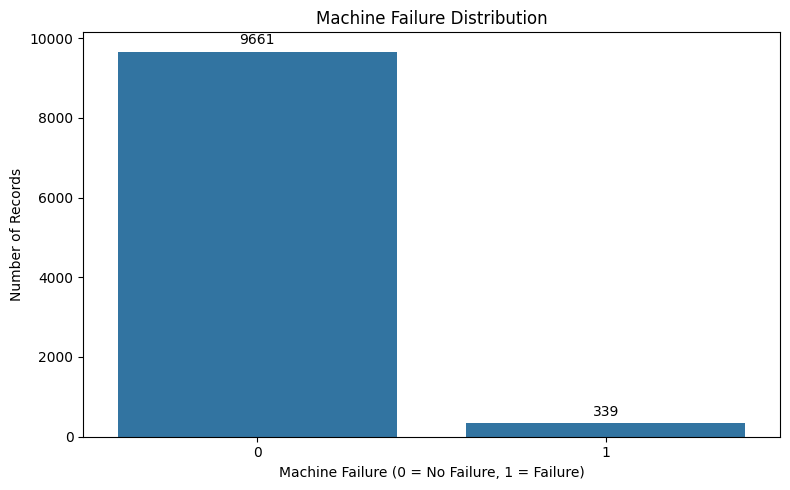

In [8]:
# Purpose: Analyze machine failure distribution and identify class imbalance.

failure_counts = df["Machine failure"].value_counts().sort_index()
failure_percentages = df["Machine failure"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage": failure_percentages
})

display(target_summary)

# Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="Machine failure")

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 4. Target Variable Distribution

The target variable `Machine failure` shows a significant class imbalance.

- **No Failure (0):** 9,661 records (96.61%).
- **Failure (1):** 339 records (3.39%).

The dataset is highly imbalanced, with failure cases representing only a small proportion of observations.

**Business implication:** A model that predicts every machine as operational could achieve 96.61% accuracy while failing to identify any actual machine failures.

Therefore, accuracy alone is not a reliable evaluation metric. We will prioritize Recall, Precision, F1-score, and PR-AUC to assess failure detection performance.

We will also investigate suitable class-imbalance handling techniques during model development.

In [10]:
# Purpose: Analyze the distribution of numerical operating parameters.

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Display descriptive statistics
display(df[numerical_features].describe())

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


## 5. Numerical Feature Analysis

The descriptive statistics provide an overview of the five machine operating parameters.

Key observations:

- **Air Temperature:** Mean of 300.00 K, with relatively low variation.
- **Process Temperature:** Mean of 310.01 K, indicating stable temperature measurements.
- **Rotational Speed:** Mean of 1538.78 rpm, with a maximum of 2886 rpm.
- **Torque:** Mean of 39.99 Nm, with values ranging from 3.8 to 76.6 Nm.
- **Tool Wear:** Mean of 107.95 minutes, ranging from 0 to 253 minutes.

The numerical features have different measurement scales and distributions. This will be considered during preprocessing, particularly when preparing data for Logistic Regression and ANN.

The maximum rotational speed and other extreme values will be investigated further rather than automatically treated as errors.

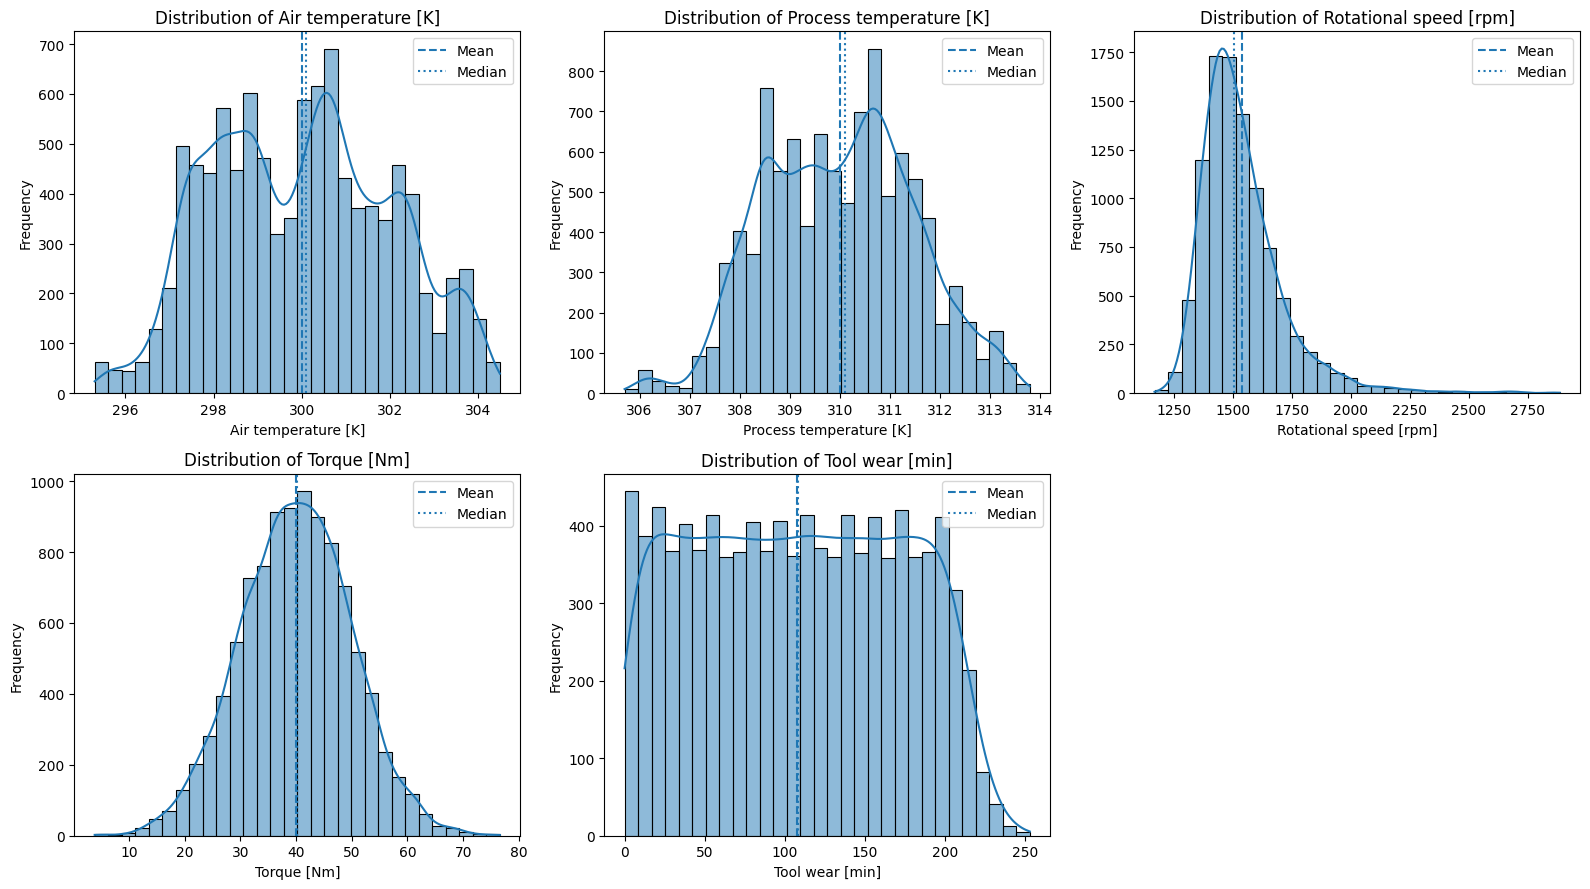

In [11]:
# Visualize numerical feature distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.histplot(data=df, x=column, bins=30, kde=True, ax=axes[i])

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

    # Add mean and median reference lines
    axes[i].axvline(df[column].mean(), linestyle="--", label="Mean")
    axes[i].axvline(df[column].median(), linestyle=":", label="Median")
    axes[i].legend()

# Remove unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

In [12]:
# Hidden missing-value detection

# Purpose: Identify hidden missing-value representations in the dataset.

missing_tokens = [
    "", " ", "NA", "N/A", "NaN", "nan", "NAN",
    "NULL", "null", "None", "none", "?"
]

hidden_missing = {}

for column in df.columns:
    if df[column].dtype == "object":

        values = df[column].astype("string").str.strip()

        count = values.isin(missing_tokens).sum()

        if count > 0:
            hidden_missing[column] = count

print("Hidden Missing Values:")

if hidden_missing:
    display(pd.Series(hidden_missing, name="Count"))
else:
    print("No hidden missing-value representations found.")

print("\nTotal Hidden Missing Values:", sum(hidden_missing.values()))

Hidden Missing Values:
No hidden missing-value representations found.

Total Hidden Missing Values: 0


## Hidden Missing-Value Detection

Standard null checks may not identify missing values represented as text, such as `NA`, `N/A`, `NaN`, `NULL`, `None`, question marks, or empty strings.

To address this, additional validation was performed on categorical columns by checking for common hidden missing-value representations.

**Findings:**
- Hidden missing values detected: 0
- No suspicious missing-value tokens were found.

**Conclusion:** No hidden missing-value representations were identified. Therefore, no additional missing-value cleaning is required at this stage.

In [13]:
import re

# Purpose: Detect hidden missing values using regex patterns.

missing_pattern = re.compile(
    r"^\s*(?:"
    r"na|n/a|nan|null|none|"
    r"missing|not available|not applicable|"
    r"undefined|unknown|"
    r"[-]+|[?]+|"
    r"0|"
    r")\s*$",
    flags=re.IGNORECASE
)

hidden_missing_results = {}

for column in df.columns:

    if df[column].dtype == "object" or pd.api.types.is_string_dtype(df[column]):

        values = df[column].astype("string")

        matches = values.str.fullmatch(missing_pattern, na=False)

        if matches.any():
            hidden_missing_results[column] = {
                "Count": int(matches.sum()),
                "Values": values[matches].unique().tolist()
            }

print("REGEX-BASED HIDDEN MISSING VALUE AUDIT")
print("-" * 50)

if hidden_missing_results:
    for column, result in hidden_missing_results.items():
        print(f"\nColumn: {column}")
        print(f"Count: {result['Count']}")
        print(f"Values: {result['Values']}")
else:
    print("No regex-based hidden missing values detected.")

print("\nTotal Hidden Missing Values:",
      sum(x["Count"] for x in hidden_missing_results.values()))

REGEX-BASED HIDDEN MISSING VALUE AUDIT
--------------------------------------------------
No regex-based hidden missing values detected.

Total Hidden Missing Values: 0


## 4. Advanced Hidden Missing-Value Detection Using Regex

To strengthen the data-quality assessment, Regular Expressions (Regex) were used to identify hidden missing-value representations that may not be detected through standard null checks.

The validation covered common representations such as:
- NA, N/A, NaN and NULL
- None and Undefined
- Missing and Unknown
- Empty strings, question marks, and placeholder dashes

**Findings:**
- Regex-based hidden missing values: 0
- No suspicious missing-value representations were detected in the categorical columns.

**Conclusion:** Both standard and regex-based checks indicate that the dataset contains no detectable missing-value representations. No missing-value treatment is required.

In [15]:
# Outlier detection using IQR

# Purpose: Quantify potential outliers using the Interquartile Range (IQR) method.

outlier_results = []

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


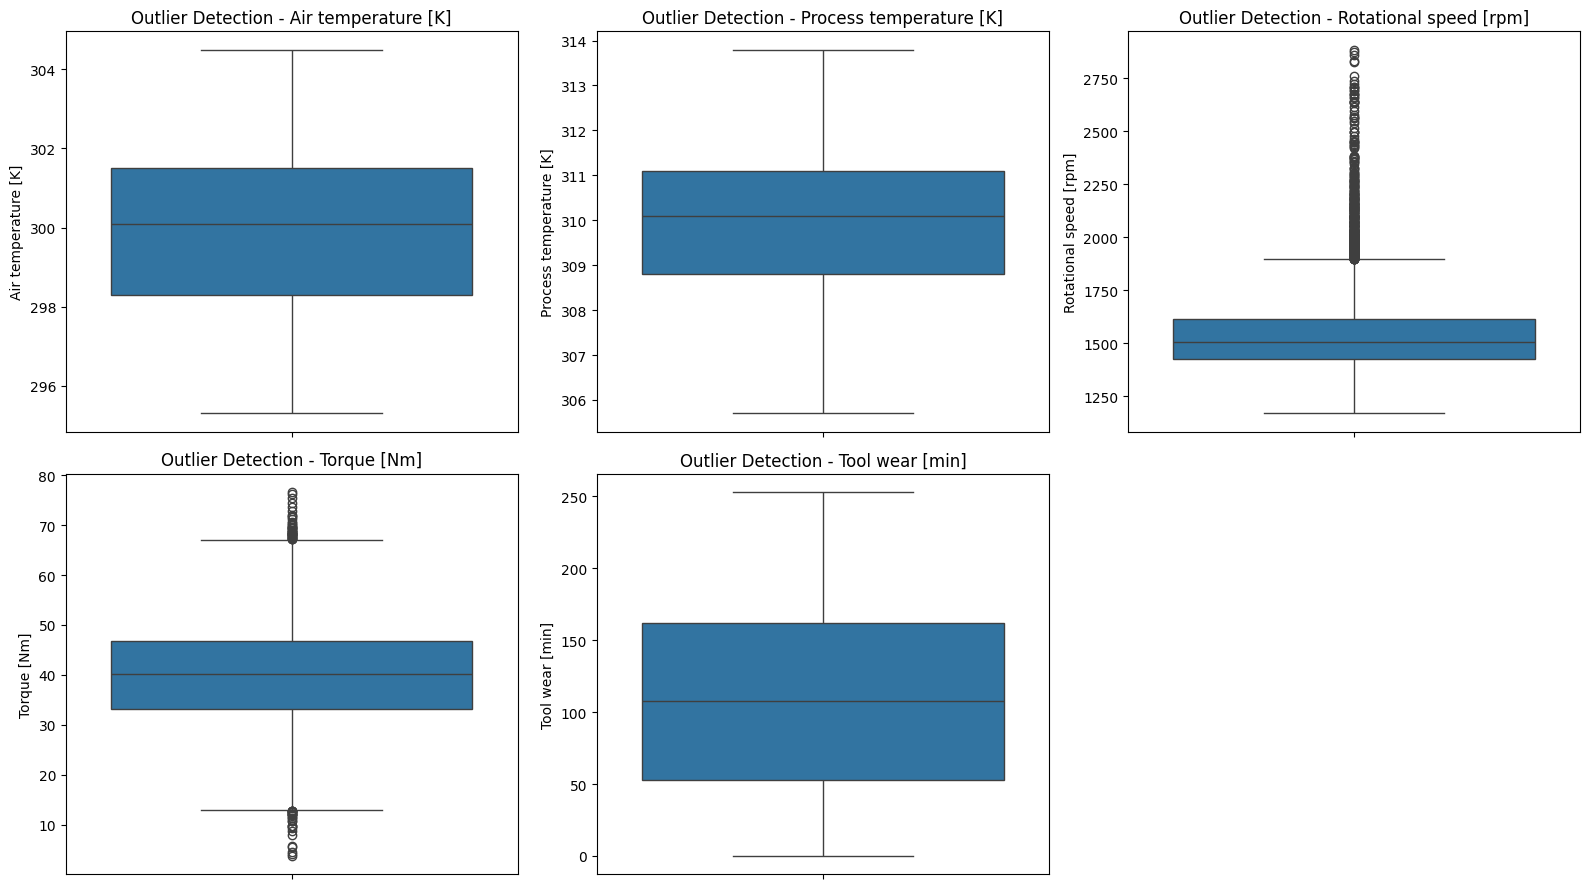

In [16]:
# Outlier detection using boxplots

# Purpose: Visualize potential outliers in numerical operating parameters.

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):

    sns.boxplot(y=df[column], ax=axes[i])

    axes[i].set_title(f"Outlier Detection - {column}")
    axes[i].set_ylabel(column)

plt.delaxes(axes[5])

plt.tight_layout()
plt.show()

## Outlier Analysis and Treatment Decision

The IQR method identified potential outliers in Rotational Speed and Torque, while Air Temperature, Process Temperature, and Tool Wear showed no outliers.

Key findings:
- Rotational Speed: 418 outliers (4.18%).
- Torque: 69 outliers (0.69%).
- Other numerical features: No detected outliers.

These extreme observations may represent genuine machine operating conditions rather than data-entry errors.

**Treatment Decision:**

We will retain the identified outliers at this stage instead of automatically removing or capping them.

Since unusual rotational speeds and torque levels may contain useful information about machine failure conditions, their relationship with the target variable will be investigated before making any treatment decisions.

In [17]:
# Outliers against machine failure

# Purpose: Examine the relationship between potential outliers and machine failures.

outlier_features = ["Rotational speed [rpm]", "Torque [Nm]"]

outlier_comparison = []

for column in outlier_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    for status, mask in [
        ("Outlier", outlier_mask),
        ("Normal", ~outlier_mask)
    ]:

        total = mask.sum()
        failures = df.loc[mask, "Machine failure"].sum()

        outlier_comparison.append({
            "Feature": column,
            "Group": status,
            "Records": total,
            "Failures": failures,
            "Failure Rate (%)": round(
                failures / total * 100, 2
            ) if total > 0 else 0
        })

comparison_df = pd.DataFrame(outlier_comparison)

display(comparison_df)

,Feature,Group,Records,Failures,Failure Rate (%)
0,Rotational speed [rpm],Outlier,418,35,8.37
1,Rotational speed [rpm],Normal,9582,304,3.17
2,Torque [Nm],Outlier,69,62,89.86
3,Torque [Nm],Normal,9931,277,2.79


## Outlier Relationship with Machine Failure

To understand whether extreme operating conditions are associated with machine failures, the detected outliers were compared against normal observations.

**Key Findings:**

1. **Rotational Speed:**
   - Outlier failure rate: 8.37%.
   - Normal observation failure rate: 3.17%.
   - Outlier observations show a higher failure rate than normal observations.

2. **Torque:**
   - Outlier failure rate: 89.86%.
   - Normal observation failure rate: 2.79%.
   - Torque outliers show a significantly higher failure rate.

**Interpretation:**

Extreme rotational speeds and torque measurements may contain valuable information for identifying potential machine failures. The relationship is particularly strong for torque outliers.

**Treatment Decision:**

We will retain these observations without removing or capping them, as they may represent meaningful machine operating conditions.

These findings indicate statistical associations, not proof that extreme values directly cause machine failures.

In [18]:
# Analyze lower and upper outliers separately

# Purpose: Compare failure rates across lower, normal, and upper operating ranges.

directional_results = []

for column in outlier_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    conditions = [
        df[column] < lower_bound,
        df[column] > upper_bound
    ]

    groups = ["Lower Outlier", "Upper Outlier"]

    for condition, group in zip(conditions, groups):

        subset = df[condition]

        directional_results.append({
            "Feature": column,
            "Group": group,
            "Records": len(subset),
            "Failures": subset["Machine failure"].sum(),
            "Failure Rate (%)": round(
                subset["Machine failure"].mean() * 100, 2
            ) if len(subset) > 0 else 0
        })

    normal = df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]

    directional_results.append({
        "Feature": column,
        "Group": "Normal",
        "Records": len(normal),
        "Failures": normal["Machine failure"].sum(),
        "Failure Rate (%)": round(
            normal["Machine failure"].mean() * 100, 2
        )
    })

directional_summary = pd.DataFrame(directional_results)

display(directional_summary)

,Feature,Group,Records,Failures,Failure Rate (%)
0,Rotational speed [rpm],Lower Outlier,0,0,0.00
1,Rotational speed [rpm],Upper Outlier,418,35,8.37
2,Rotational speed [rpm],Normal,9582,304,3.17
3,Torque [Nm],Lower Outlier,28,25,89.29
4,Torque [Nm],Upper Outlier,41,37,90.24
5,Torque [Nm],Normal,9931,277,2.79


## Directional Outlier Analysis

The lower and upper outliers were analyzed separately to understand their relationship with machine failures.

**Key Findings:**

1. **Rotational Speed:**
   - No lower outliers were detected.
   - Upper outliers: 418 records, with an 8.37% failure rate.
   - Normal observations: 3.17% failure rate.

2. **Torque:**
   - Lower outliers: 28 records, with an 89.29% failure rate.
   - Upper outliers: 41 records, with a 90.24% failure rate.
   - Normal observations: 2.79% failure rate.

**Interpretation:**

Both unusually low and high torque measurements show a significantly higher association with machine failures. Upper rotational-speed outliers also show an increased failure rate.

**Final Treatment Decision:**

All identified outliers will be retained because they may represent meaningful abnormal machine operating conditions.

Removing or capping these observations could eliminate valuable failure-related information and negatively affect model performance.

,Type,Records,Failures,Failure_Rate
0,H,1003,21,2.09
1,L,6000,235,3.92
2,M,2997,83,2.77


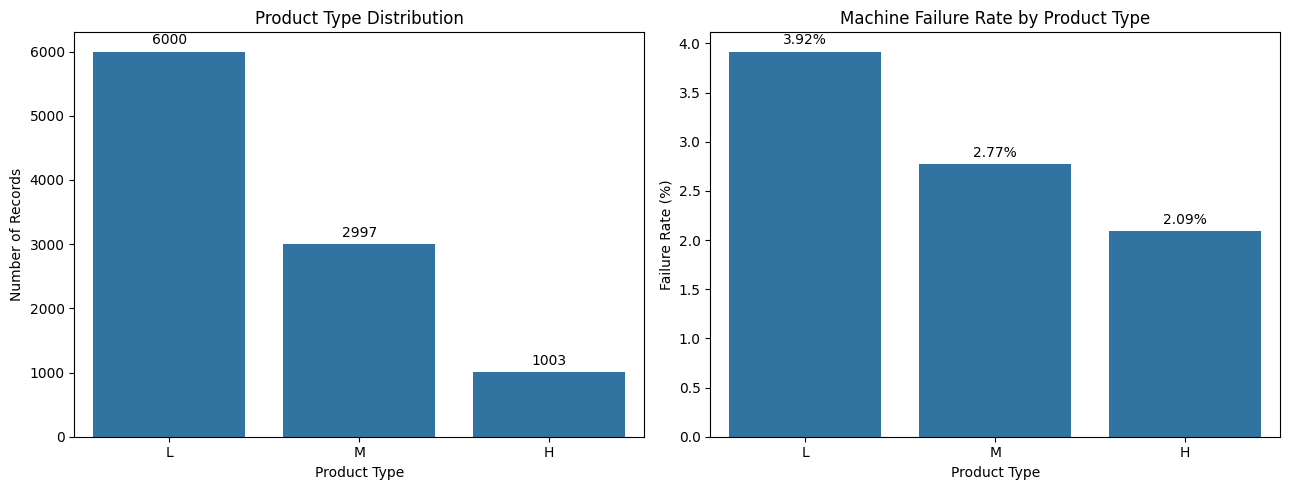

In [19]:
# Categorical feature analysis

# Purpose: Analyze product type distribution and machine failure rates.

type_summary = df.groupby("Type").agg(
    Records=("Machine failure", "count"),
    Failures=("Machine failure", "sum"),
    Failure_Rate=("Machine failure", "mean")
).reset_index()

type_summary["Failure_Rate"] *= 100

display(type_summary.round(2))

# Visualize product type distribution and failure rates
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Product type counts
ax1 = sns.countplot(data=df, x="Type", order=["L", "M", "H"], ax=axes[0])

for container in ax1.containers:
    ax1.bar_label(container, fmt="%.0f", padding=3)

ax1.set_title("Product Type Distribution")
ax1.set_xlabel("Product Type")
ax1.set_ylabel("Number of Records")

# Failure rate by product type
ax2 = sns.barplot(
    data=type_summary,
    x="Type",
    y="Failure_Rate",
    order=["L", "M", "H"],
    ax=axes[1]
)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.2f%%", padding=3)

ax2.set_title("Machine Failure Rate by Product Type")
ax2.set_xlabel("Product Type")
ax2.set_ylabel("Failure Rate (%)")

plt.tight_layout()
plt.show()

## Categorical Feature Analysis

The product quality category (`Type`) was analyzed to understand its distribution and relationship with machine failures.

The dataset contains three categories:
- L – Low Quality
- M – Medium Quality
- H – High Quality

**Key Findings:**

- **Type L:** 6,000 records, 235 failures, 3.92% failure rate.
- **Type M:** 2,997 records, 83 failures, 2.77% failure rate.
- **Type H:** 1,003 records, 21 failures, 2.09% failure rate.

**Interpretation:**

Type L has the highest observed failure rate, whereas Type H has the lowest.

These findings indicate an association between product category and machine failure, but do not establish a causal relationship.

The `Type` feature will be retained for model development and appropriately encoded during preprocessing.

,No Failure,Failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


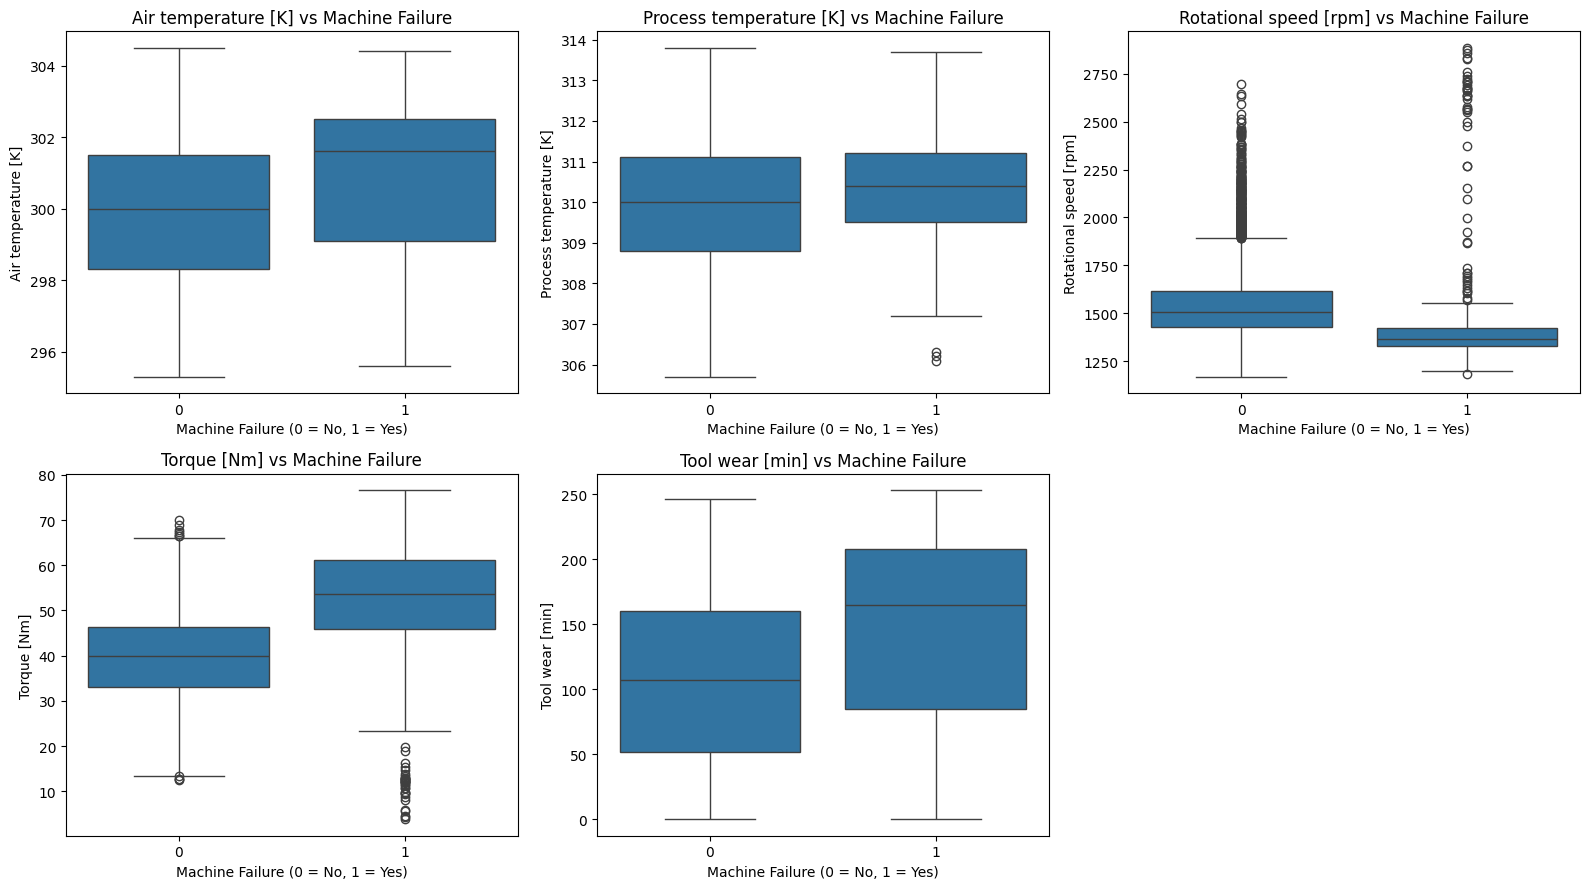

In [20]:
# Operating parameters vs machine failure

# Purpose: Compare operating parameters across machine failure classes.

failure_comparison = df.groupby("Machine failure")[numerical_features].mean().T

failure_comparison.columns = ["No Failure", "Failure"]

display(failure_comparison.round(2))

# Visualize operating parameters against machine failure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):

    ax = sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        ax=axes[i]
    )

    ax.set_title(f"{column} vs Machine Failure")
    ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
    ax.set_ylabel(column)

plt.delaxes(axes[5])

plt.tight_layout()
plt.show()

## Operating Parameters vs Machine Failure

The numerical operating parameters were compared across machines with and without failures using descriptive statistics and boxplots.

**Key Findings:**

- **Air Temperature:** Slightly higher average temperature in failed machines (300.89 K).
- **Process Temperature:** Only a small difference between the two groups.
- **Rotational Speed:** Failed machines show a lower average speed (1496.49 rpm).
- **Torque:** Failed machines show higher average torque (50.17 Nm).
- **Tool Wear:** Failed machines have higher average tool wear (143.78 minutes).

**Interpretation:**

Torque and Tool Wear show noticeable increases in failed machines, while Rotational Speed shows a decrease. Temperature measurements show comparatively smaller differences.

**Conclusion:**

Torque, Tool Wear, and Rotational Speed appear to be important operating parameters for further investigation in machine failure prediction.

These observations indicate associations, not direct causation. All five numerical features will be retained for model development.

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.00,0.88,0.02,-0.01,0.01,0.08
Process temperature [K],0.88,1.00,0.02,-0.01,0.01,0.04
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00,-0.04
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00,0.19
Tool wear [min],0.01,0.01,0.00,-0.00,1.00,0.11
Machine failure,0.08,0.04,-0.04,0.19,0.11,1.00


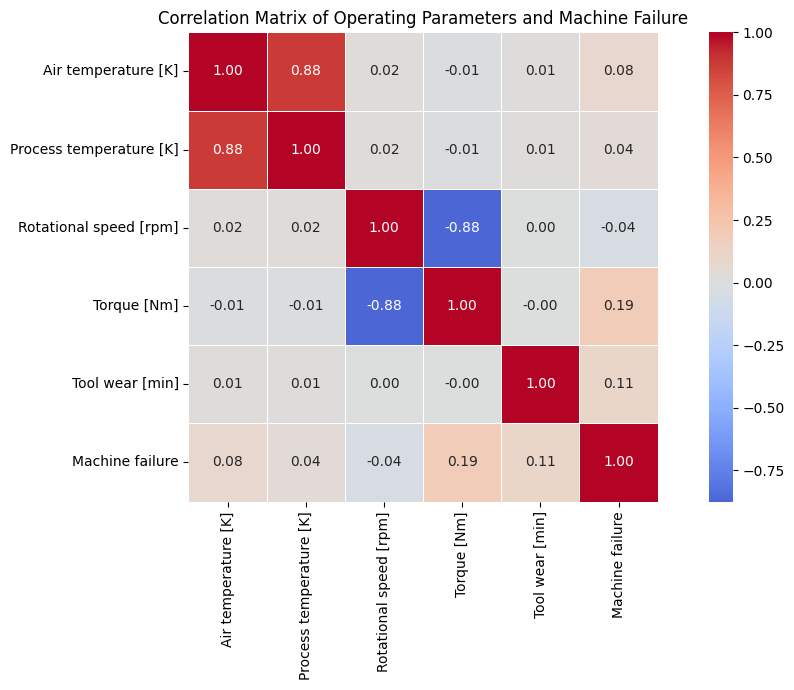

In [21]:
# Correlation Analysis

# Purpose: Analyze correlations between numerical features and machine failure.

correlation_features = numerical_features + ["Machine failure"]

correlation_matrix = df[correlation_features].corr(method="pearson")

# Display correlation values
display(correlation_matrix.round(2))

# Visualize the correlation matrix
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix of Operating Parameters and Machine Failure")
plt.tight_layout()
plt.show()

## Correlation Analysis

Pearson correlation was used to examine linear relationships between numerical operating parameters and machine failure.

**Key Findings:**

- Torque has the highest positive correlation with machine failure (0.19).
- Tool Wear shows a positive correlation of 0.11.
- Air Temperature and Process Temperature show weak positive correlations.
- Rotational Speed has a weak negative correlation (-0.04).

**Feature Relationships:**

- Air Temperature and Process Temperature show a strong positive correlation (0.88).
- Rotational Speed and Torque show a strong negative correlation (-0.88).

**Interpretation:**

Although individual features show relatively weak linear correlations with machine failure, they may still contribute to prediction through nonlinear relationships and feature interactions.

The strong correlations between certain input features will also be considered during model development, particularly when evaluating multicollinearity.

**Conclusion:**

All five numerical operating parameters will be retained for further analysis. Feature importance and predictive contribution will be evaluated using the developed models rather than relying solely on correlation values.

In [22]:
# Feature selection and data leakage audit

# Purpose: Identify valid input features and prevent data leakage.

# Identifier columns
identifier_columns = ["UDI", "Product ID"]

# Target variable
target_column = "Machine failure"

# Failure-mode columns that must be excluded
leakage_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Valid input features
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Verify that all expected columns exist
expected_columns = (
    identifier_columns + feature_columns +
    [target_column] + leakage_columns
)

assert set(expected_columns) == set(df.columns), "Unexpected dataset columns detected."

# Create feature and target datasets
X = df[feature_columns].copy()
y = df[target_column].copy()

# Display feature selection summary
feature_audit = pd.DataFrame({
    "Column": expected_columns,
    "Role": (
        ["Identifier"] * len(identifier_columns) +
        ["Input Feature"] * len(feature_columns) +
        ["Target"] +
        ["Excluded - Data Leakage"] * len(leakage_columns)
    )
})

display(feature_audit)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Leakage Columns Included:",
      any(column in X.columns for column in leakage_columns))

,Column,Role
0,UDI,Identifier
1,Product ID,Identifier
2,Type,Input Feature
3,Air temperature [K],Input Feature
4,Process temperature [K],Input Feature
5,Rotational speed [rpm],Input Feature
6,Torque [Nm],Input Feature
7,Tool wear [min],Input Feature
8,Machine failure,Target
9,TWF,Excluded - Data Leakage


Input Features Shape: (10000, 6)
Target Shape: (10000,)
Leakage Columns Included: False


## Feature Selection and Validation

The feature selection audit confirms that six valid input features and one target variable have been selected.

Identifier columns (`UDI`, `Product ID`) and five failure-mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) have been excluded.

The leakage validation confirms that none of the excluded failure-mode columns are present in the input features.

**Conclusion:** The selected dataset is ready for train-test splitting and subsequent preprocessing.

In [23]:
# Train-Test Split

# Purpose: Split the dataset while preserving machine failure class proportions.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Compare class distributions
split_summary = pd.DataFrame({
    "Training Count": y_train.value_counts().sort_index(),
    "Training (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Testing Count": y_test.value_counts().sort_index(),
    "Testing (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

display(split_summary.round(2))

Training Features: (8000, 6)
Testing Features: (2000, 6)

Training Target: (8000,)
Testing Target: (2000,)


,Training Count,Training (%),Testing Count,Testing (%)
Machine failure,,,,
0,7729,96.61,1932,96.6
1,271,3.39,68,3.4


## Train-Test Split

The dataset was divided into training (80%) and testing (20%) sets using stratified sampling.

Stratification was applied to preserve the original machine failure distribution across both datasets.

**Results:**
- Training records: 8,000
- Testing records: 2,000
- Training failure cases: 271
- Testing failure cases: 68

**Conclusion:**

The class distribution is consistently maintained across both sets. The test dataset will remain untouched during model training, preprocessing decisions, and hyperparameter tuning to ensure an unbiased final evaluation.

In [24]:
# Create a validation set

# Purpose: Create a validation set for model selection and tuning.

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Verify dataset dimensions
print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)
print("Testing Features:", X_test.shape)

# Compare class distributions
validation_summary = pd.DataFrame({
    "Training": y_train.value_counts().sort_index(),
    "Validation": y_val.value_counts().sort_index(),
    "Testing": y_test.value_counts().sort_index()
})

display(validation_summary)

Training Features: (6400, 6)
Validation Features: (1600, 6)
Testing Features: (2000, 6)


,Training,Validation,Testing
Machine failure,,,
0,6183,1546,1932
1,217,54,68


## Training, Validation and Testing Split

The original dataset was divided into three subsets using stratified sampling:

- Training: 64% (6,400 records)
- Validation: 16% (1,600 records)
- Testing: 20% (2,000 records)

**Purpose of Each Dataset:**

- Training data: Model fitting and learning.
- Validation data: Model selection, hyperparameter tuning and threshold evaluation.
- Testing data: Final unbiased model evaluation.

The failure-class distribution is maintained across all three subsets.

**Conclusion:** The data is ready for preprocessing and model development. The test dataset will remain untouched until final evaluation.

In [25]:
# Feature preprocessing

# Purpose: Scale numerical features and encode categorical features.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical columns
numerical_columns = numerical_features
categorical_columns = ["Type"]

# Define preprocessing transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
processed_feature_names = preprocessor.get_feature_names_out()

# Display transformed datasets
print("Training Shape:", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("\nTransformed Features:")
print(processed_feature_names)

Training Shape: (6400, 8)
Validation Shape: (1600, 8)
Testing Shape: (2000, 8)

Transformed Features:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


## Feature Preprocessing

Applied StandardScaler to the five numerical features and One-Hot Encoding to the categorical feature `Type`.

The categorical feature was converted into three binary columns: `Type_H`, `Type_L`, and `Type_M`.

The preprocessing pipeline was fitted exclusively on the training dataset and applied to the validation and testing datasets to prevent data leakage.

Final feature dimensions:
- Training: 6,400 × 8
- Validation: 1,600 × 8
- Testing: 2,000 × 8

The final dataset contains eight model-ready features, with all identified outliers retained to preserve potentially meaningful failure-related information.

## Outlier Treatment Decision

The IQR method identified potential outliers in Rotational Speed and Torque.

Further investigation revealed higher machine failure rates among these observations, particularly for lower and upper Torque outliers.

Since these extreme values may represent meaningful machine operating conditions rather than data errors, they will be retained without removal or capping.

StandardScaler will be applied to numerical features during preprocessing. However, scaling does not eliminate the influence of extreme observations.

**Conclusion:** All identified outliers are retained to preserve potentially valuable failure-related information. Their influence will be considered during model evaluation.

# Phase 2 — ML and ANN Development

## Build the Logistic Regression baseline model

In [26]:
# Purpose: Train a Logistic Regression baseline classifier.

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [28]:
# Validation predictions

# Purpose: Generate predictions and probabilities on validation data.

y_val_pred = logistic_model.predict(X_val_processed)

y_val_prob = logistic_model.predict_proba(X_val_processed)[:, 1]

print("Validation predictions generated successfully!")
print("Predictions Shape:", y_val_pred.shape)
print("Probability Shape:", y_val_prob.shape)

Validation predictions generated successfully!
Predictions Shape: (1600,)
Probability Shape: (1600,)


In [29]:
# Purpose: Evaluate Logistic Regression using validation metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("LOGISTIC REGRESSION - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_val_prob), 4))

cm = confusion_matrix(y_val, y_val_pred)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy: 0.8231
Precision: 0.1433
Recall: 0.8519
F1-Score: 0.2453
ROC-AUC: 0.8927
PR-AUC: 0.4197

Confusion Matrix:
[[1271  275]
 [   8   46]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.82      0.90      1546
     Failure       0.14      0.85      0.25        54

    accuracy                           0.82      1600
   macro avg       0.57      0.84      0.57      1600
weighted avg       0.97      0.82      0.88      1600



## Logistic Regression — Validation Evaluation

The Logistic Regression model was evaluated on 1,600 validation records using a default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 82.31%
- Precision: 14.33%
- Recall: 85.19%
- F1-Score: 24.53%
- ROC-AUC: 0.8927
- PR-AUC: 0.4197

**Confusion Matrix Analysis:**
- True Negatives: 1,271
- False Positives: 275
- False Negatives: 8
- True Positives: 46

**Business Interpretation:**

The model successfully identified 46 of 54 actual machine failures, achieving high recall of 85.19%. However, its low precision indicates that many failure alerts are false positives, potentially resulting in unnecessary maintenance inspections.

**Conclusion:**

Logistic Regression provides a useful baseline for detecting machine failures. Further model comparison and threshold optimization are required to improve precision while maintaining high recall.

In [30]:
# Random Forest model

# Purpose: Train a Random Forest classifier for model comparison.

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [31]:
# Purpose: Generate Random Forest predictions on validation data.

y_rf_val_pred = rf_model.predict(X_val_processed)

y_rf_val_prob = rf_model.predict_proba(X_val_processed)[:, 1]

print("Random Forest validation predictions generated!")
print("Predictions Shape:", y_rf_val_pred.shape)
print("Probability Shape:", y_rf_val_prob.shape)

Random Forest validation predictions generated!
Predictions Shape: (1600,)
Probability Shape: (1600,)


In [32]:
# Purpose: Evaluate Random Forest using validation metrics.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

print("RANDOM FOREST - VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_rf_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_rf_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_rf_val_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_val, y_rf_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_rf_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_rf_val_prob), 4))

cm_rf = confusion_matrix(y_val, y_rf_val_pred)

print("\nConfusion Matrix:")
print(cm_rf)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_rf_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

RANDOM FOREST - VALIDATION RESULTS
Accuracy: 0.9788
Precision: 0.8846
Recall: 0.4259
F1-Score: 0.575
ROC-AUC: 0.964
PR-AUC: 0.7347

Confusion Matrix:
[[1543    3]
 [  31   23]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1546
     Failure       0.88      0.43      0.57        54

    accuracy                           0.98      1600
   macro avg       0.93      0.71      0.78      1600
weighted avg       0.98      0.98      0.98      1600



## Random Forest — Validation Evaluation

The Random Forest model was evaluated on 1,600 validation records using the default classification threshold of 0.5.

**Evaluation Results:**
- Accuracy: 97.88%
- Precision: 88.46%
- Recall: 42.59%
- F1-Score: 57.50%
- ROC-AUC: 0.9640
- PR-AUC: 0.7347

**Confusion Matrix Analysis:**
- True Negatives: 1,543
- False Positives: 3
- False Negatives: 31
- True Positives: 23

**Business Interpretation:**

Random Forest achieves high precision and generates very few false alarms. However, it detects only 23 of the 54 actual failures, missing 31 failures.

Although its ROC-AUC and PR-AUC indicate strong ranking performance, its default classification threshold does not provide sufficient failure detection for a recall-focused maintenance strategy.

**Conclusion:**

Random Forest demonstrates stronger overall discrimination and precision than Logistic Regression. However, its low failure recall requires further investigation through decision-threshold optimization.

In [33]:
# ANN model architecture

# Purpose: Build an Artificial Neural Network for machine failure classification.

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)